<a href="https://colab.research.google.com/github/yashinrush/dbms/blob/main/ML_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import datetime as dt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import seaborn as sns

In [ ]:
df = pd.read_csv('E-commerece sales data 2024.csv', encoding='unicode_escape')


In [ ]:
df.head()


,user id,product id,Interaction type,Time stamp,Unnamed: 4
0,1.0,4c69b61db1fc16e7013b43fc926e502d,purchase,10/10/2023 8:00,NaN
1,2.0,66d49bbed043f5be260fa9f7fbff5957,view,11/10/2023 8:00,NaN
2,3.0,2c55cae269aebf53838484b0d7dd931a,like,12/10/2023 8:00,NaN
3,4.0,18018b6bc416dab347b1b7db79994afa,view,13/10/2023 8:00,NaN
4,5.0,e04b990e95bf73bbe6a3fa09785d7cd0,like,14/10/2023 8:00,NaN


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3294 entries, 0 to 3293
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user id           2999 non-null   float64
 1   product id        2999 non-null   object 
 2   Interaction type  2871 non-null   object 
 3   Time stamp        2999 non-null   object 
 4   Unnamed: 4        0 non-null      float64
dtypes: float64(2), object(3)
memory usage: 128.8+ KB


In [ ]:
df = df.drop(columns=['Unnamed: 4'], errors='ignore')
display(df.head())

,user id,product id,Interaction type,Time stamp
0,1.0,4c69b61db1fc16e7013b43fc926e502d,purchase,10/10/2023 8:00
1,2.0,66d49bbed043f5be260fa9f7fbff5957,view,11/10/2023 8:00
2,3.0,2c55cae269aebf53838484b0d7dd931a,like,12/10/2023 8:00
3,4.0,18018b6bc416dab347b1b7db79994afa,view,13/10/2023 8:00
4,5.0,e04b990e95bf73bbe6a3fa09785d7cd0,like,14/10/2023 8:00


In [ ]:
df.isnull().sum()


,0
user id,295
product id,295
Interaction type,423
Time stamp,295


In [ ]:
df.dtypes


,0
user id,float64
product id,object
Interaction type,object
Time stamp,object


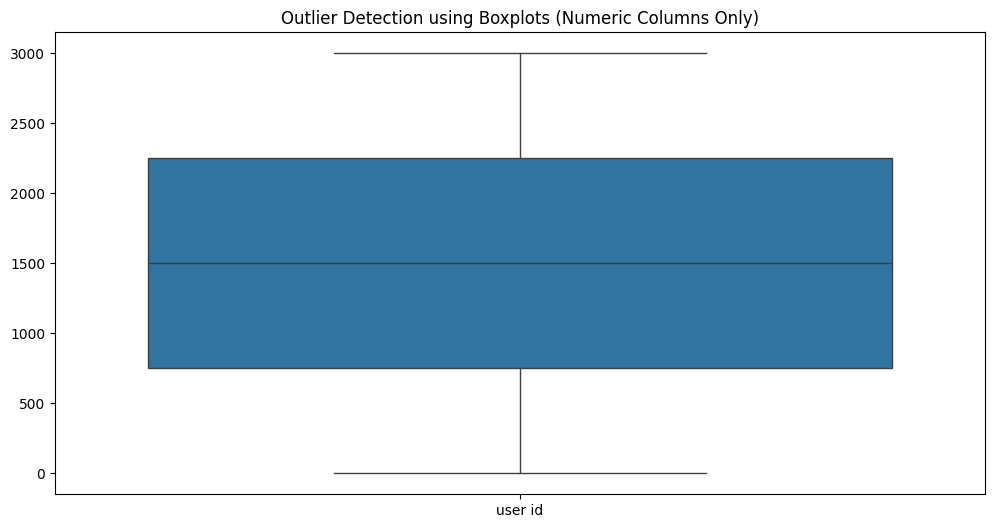


Number of Outliers per Numeric Feature:
 user id    0
dtype: int64


In [ ]:
# Select numeric columns only
df_numeric = df.select_dtypes(include=['int64', 'float64'])

# Visualize outliers
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_numeric)
plt.title("Outlier Detection using Boxplots (Numeric Columns Only)")
plt.show()

# Identify outliers using IQR
Q1 = df_numeric.quantile(0.25)
Q3 = df_numeric.quantile(0.75)
IQR = Q3 - Q1

# Count outliers per column
outliers = ((df_numeric < (Q1 - 1.5 * IQR)) | (df_numeric > (Q3 + 1.5 * IQR))).sum()
print("\nNumber of Outliers per Numeric Feature:\n", outliers)

In [ ]:
# Drop rows where numeric features (like 'user id') are missing to allow scaling
df_capped = df_numeric.dropna()

# Scale the cleaned numeric data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_capped)
print("Data normalized using StandardScaler. Shape of scaled data:", X_scaled.shape)

Data normalized using StandardScaler. Shape of scaled data: (2999, 1)


In [ ]:
df_normalized = pd.DataFrame(X_scaled, columns=df_capped.columns)

print("\nSample of Normalized Data:")
display(df_normalized.head())

print("\nMean of each feature after normalization:\n", df_normalized.mean())
print("\nStandard deviation of each feature after normalization:\n", df_normalized.std())


Sample of Normalized Data:


,user id
0,-1.731473
1,-1.730318
2,-1.729163
3,-1.728008
4,-1.726853



Mean of each feature after normalization:
 user id    0.0
dtype: float64

Standard deviation of each feature after normalization:
 user id    1.000167
dtype: float64


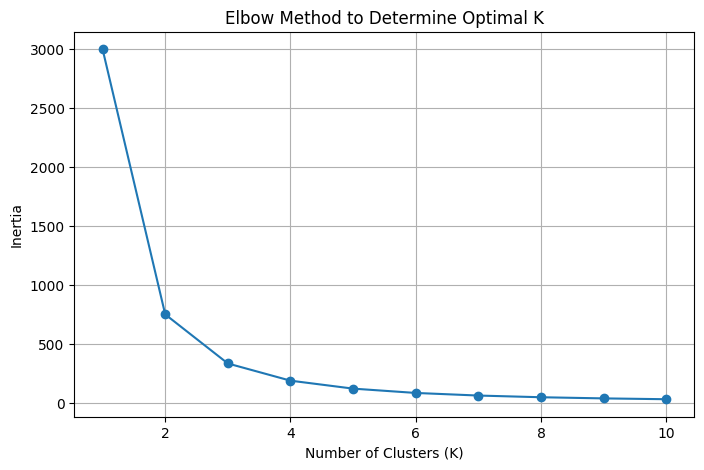

In [ ]:
inertia = []
K = range(1, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Plot the Elbow curve
plt.figure(figsize=(8, 5))
plt.plot(K, inertia, marker='o')
plt.title("Elbow Method to Determine Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.grid(True)
plt.show()

In [ ]:
from sklearn.metrics import silhouette_score

for k in range (2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    sil_score = silhouette_score(X_scaled, labels)
    print(f"K = {k} → Silhouette Score = {sil_score:.4f}")

K = 2 → Silhouette Score = 0.6265
K = 3 → Silhouette Score = 0.5897
K = 4 → Silhouette Score = 0.5714
K = 5 → Silhouette Score = 0.5603
K = 6 → Silhouette Score = 0.5529
K = 7 → Silhouette Score = 0.5470
K = 8 → Silhouette Score = 0.5435
K = 9 → Silhouette Score = 0.5405
K = 10 → Silhouette Score = 0.5368


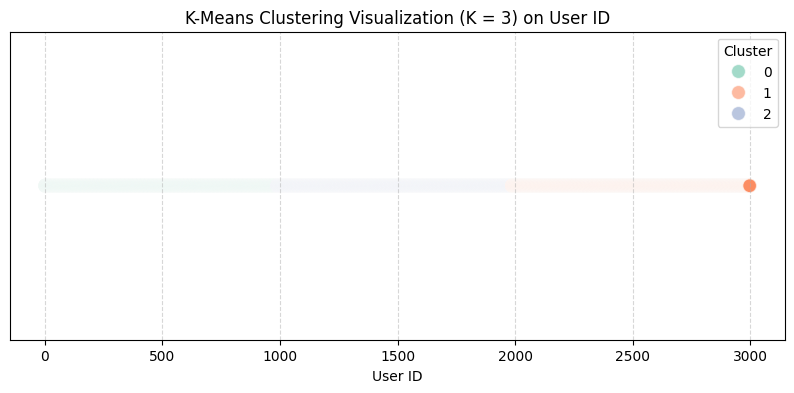

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_scaled)

# Visualize the 1D clusters along the 'user id' axis
plt.figure(figsize=(10, 4))
sns.scatterplot(
    x=df_capped['user id'],
    y=np.zeros_like(df_capped['user id']),  # Use dummy y-values to align them horizontally
    hue=labels,
    palette='Set2',
    alpha=0.6,
    s=100
)
plt.title("K-Means Clustering Visualization (K = 3) on User ID")
plt.xlabel("User ID")
plt.yticks([])  # Hide the dummy y-axis values
plt.ylabel("")
plt.legend(title='Cluster')
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.show()